# Classificação - Inadimplência no Cartão de Crédito

## 1. Definição do problema

A inadimplência é quando o cliente não paga a fatura do cartão. Para o banco isso significa prejuízo, então é importante identificar com antecedência quais clientes têm maior risco de não pagar. Com essa informação o banco pode, por exemplo, reduzir o limite, oferecer renegociação ou analisar melhor antes de liberar crédito.

**Pergunta principal:** É possível prever se um cliente vai deixar de pagar a fatura do cartão no próximo mês?

**Tipo de problema:** Classificação, pois a variável alvo tem duas categorias (paga ou não paga).

## 2. Apresentação da base de dados

- **Nome:** Default of Credit Card Clients
- **Origem:** dados de clientes de um banco de Taiwan (abril a setembro de 2005), publicados no UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
- **Registros:** 30.000 clientes
- **Colunas:** 25 (1 identificador, 23 variáveis de entrada e 1 variável alvo)

| Coluna original | Nome usado | Significado |
|---|---|---|
| ID | - | identificador do cliente (removido) |
| LIMIT_BAL | limite | limite de crédito (em dólar taiwanês) |
| SEX | sexo | 1 = masculino, 2 = feminino |
| EDUCATION | escolaridade | 1 = pós-graduação, 2 = universidade, 3 = ensino médio, 4 = outros |
| MARRIAGE | estado_civil | 1 = casado, 2 = solteiro, 3 = outros |
| AGE | idade | idade em anos |
| PAY_0 a PAY_6 | status_set a status_abr | situação do pagamento de setembro a abril: -1 = pagou em dia, 1 = um mês de atraso, 2 = dois meses de atraso, e assim por diante |
| BILL_AMT1 a 6 | fatura_set a fatura_abr | valor da fatura de cada mês |
| PAY_AMT1 a 6 | pago_set a pago_abr | valor pago em cada mês |
| default payment next month | inadimplente | **variável alvo**: 1 = não pagou no mês seguinte, 0 = pagou |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# carregando os dados (a primeira linha do arquivo e um titulo, por isso header=1)
df = pd.read_excel('../dados/credit_card_default.xls', header=1)

# renomeando as colunas para facilitar a leitura
meses = ['set', 'ago', 'jul', 'jun', 'mai', 'abr']
novos_nomes = {
    'LIMIT_BAL': 'limite',
    'SEX': 'sexo',
    'EDUCATION': 'escolaridade',
    'MARRIAGE': 'estado_civil',
    'AGE': 'idade',
    'default payment next month': 'inadimplente'
}
status_original = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
for i in range(6):
    novos_nomes[status_original[i]] = 'status_' + meses[i]
    novos_nomes['BILL_AMT' + str(i + 1)] = 'fatura_' + meses[i]
    novos_nomes['PAY_AMT' + str(i + 1)] = 'pago_' + meses[i]

df = df.rename(columns=novos_nomes)

print('Linhas:', df.shape[0])
print('Colunas:', df.shape[1])

Linhas: 30000
Colunas: 25


## 3. Análise exploratória dos dados

In [3]:
# primeiras linhas
df.head()

,ID,limite,sexo,escolaridade,estado_civil,idade,status_set,status_ago,status_jul,status_jun,...,fatura_jun,fatura_mai,fatura_abr,pago_set,pago_ago,pago_jul,pago_jun,pago_mai,pago_abr,inadimplente
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [4]:
# tipos de dados
df.dtypes

ID              int64
limite          int64
sexo            int64
escolaridade    int64
estado_civil    int64
idade           int64
status_set      int64
status_ago      int64
status_jul      int64
status_jun      int64
status_mai      int64
status_abr      int64
fatura_set      int64
fatura_ago      int64
fatura_jul      int64
fatura_jun      int64
fatura_mai      int64
fatura_abr      int64
pago_set        int64
pago_ago        int64
pago_jul        int64
pago_jun        int64
pago_mai        int64
pago_abr        int64
inadimplente    int64
dtype: object

In [5]:
# valores ausentes
print('Total de valores ausentes:', df.isnull().sum().sum())

Total de valores ausentes: 0


In [6]:
# registros duplicados (sem considerar o ID, que e sempre diferente)
print('Duplicados:', df.drop(columns='ID').duplicated().sum())

Duplicados: 35


In [7]:
# estatisticas basicas
df.describe().round(2)

,ID,limite,sexo,escolaridade,estado_civil,idade,status_set,status_ago,status_jul,status_jun,...,fatura_jun,fatura_mai,fatura_abr,pago_set,pago_ago,pago_jul,pago_jun,pago_mai,pago_abr,inadimplente
count,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,...,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00
mean,15000.50,167484.32,1.60,1.85,1.55,35.49,-0.02,-0.13,-0.17,-0.22,...,43262.95,40311.40,38871.76,5663.58,5921.16,5225.68,4826.08,4799.39,5215.50,0.22
std,8660.40,129747.66,0.49,0.79,0.52,9.22,1.12,1.20,1.20,1.17,...,64332.86,60797.16,59554.11,16563.28,23040.87,17606.96,15666.16,15278.31,17777.47,0.42
min,1.00,10000.00,1.00,0.00,0.00,21.00,-2.00,-2.00,-2.00,-2.00,...,-170000.00,-81334.00,-339603.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,7500.75,50000.00,1.00,1.00,1.00,28.00,-1.00,-1.00,-1.00,-1.00,...,2326.75,1763.00,1256.00,1000.00,833.00,390.00,296.00,252.50,117.75,0.00
50%,15000.50,140000.00,2.00,2.00,2.00,34.00,0.00,0.00,0.00,0.00,...,19052.00,18104.50,17071.00,2100.00,2009.00,1800.00,1500.00,1500.00,1500.00,0.00
75%,22500.25,240000.00,2.00,2.00,2.00,41.00,0.00,0.00,0.00,0.00,...,54506.00,50190.50,49198.25,5006.00,5000.00,4505.00,4013.25,4031.50,4000.00,0.00
max,30000.00,1000000.00,2.00,6.00,3.00,79.00,8.00,8.00,8.00,8.00,...,891586.00,927171.00,961664.00,873552.00,1684259.00,896040.00,621000.00,426529.00,528666.00,1.00


In [8]:
# valores das colunas categoricas
print('Escolaridade:', df['escolaridade'].value_counts().sort_index().to_dict())
print('Estado civil:', df['estado_civil'].value_counts().sort_index().to_dict())

Escolaridade: {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
Estado civil: {0: 54, 1: 13659, 2: 15964, 3: 323}


Na documentação da base, escolaridade só vai de 1 a 4 e estado civil de 1 a 3. Os valores 0, 5 e 6 na escolaridade e 0 no estado civil não têm significado definido, então serão tratados na preparação.

inadimplente
0    23364
1     6636
Name: count, dtype: int64

inadimplente
0    0.779
1    0.221
Name: proportion, dtype: float64


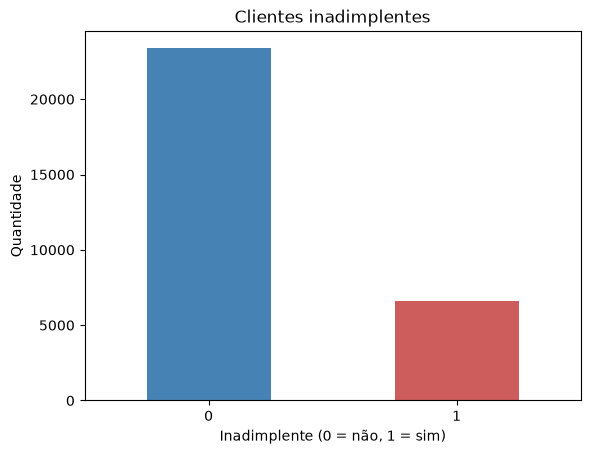

In [9]:
# distribuicao da variavel alvo
print(df['inadimplente'].value_counts())
print()
print(df['inadimplente'].value_counts(normalize=True).round(3))

df['inadimplente'].value_counts().plot(kind='bar', color=['steelblue', 'indianred'])
plt.title('Clientes inadimplentes')
plt.xlabel('Inadimplente (0 = não, 1 = sim)')
plt.ylabel('Quantidade')
plt.xticks(rotation=0)
plt.show()

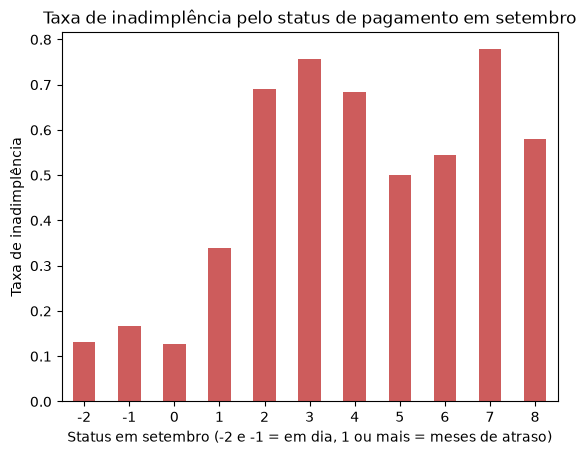

In [10]:
# taxa de inadimplencia pela situacao do pagamento em setembro
taxa = df.groupby('status_set')['inadimplente'].mean()

taxa.plot(kind='bar', color='indianred')
plt.title('Taxa de inadimplência pelo status de pagamento em setembro')
plt.xlabel('Status em setembro (-2 e -1 = em dia, 1 ou mais = meses de atraso)')
plt.ylabel('Taxa de inadimplência')
plt.xticks(rotation=0)
plt.show()

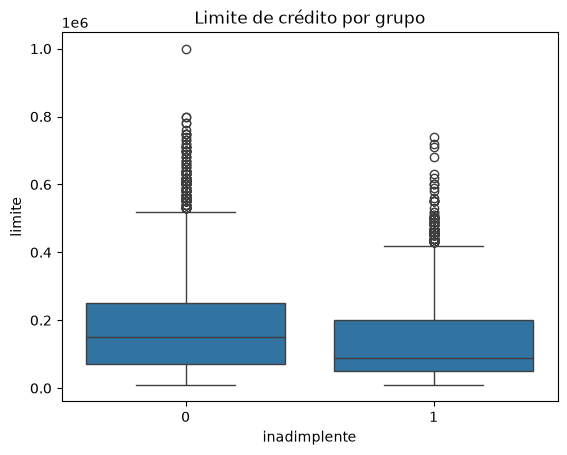

In [11]:
# limite de credito por grupo
sns.boxplot(data=df, x='inadimplente', y='limite')
plt.title('Limite de crédito por grupo')
plt.show()

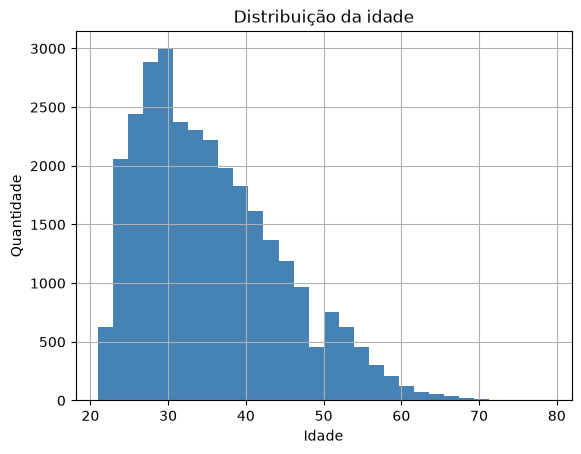

In [12]:
# histograma da idade
df['idade'].hist(bins=30, color='steelblue')
plt.title('Distribuição da idade')
plt.xlabel('Idade')
plt.ylabel('Quantidade')
plt.show()

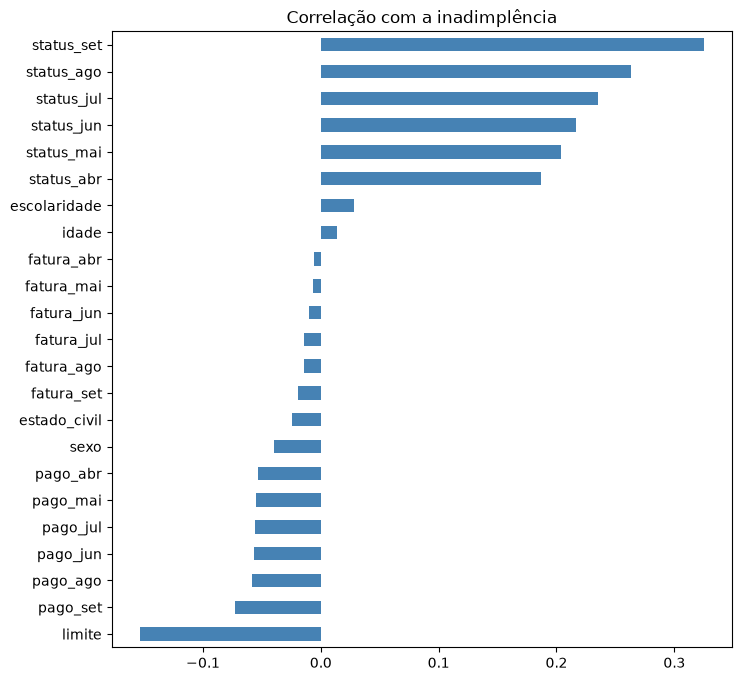

In [13]:
# correlacao de cada variavel com a inadimplencia
correlacao = df.drop(columns='ID').corr()['inadimplente'].drop('inadimplente').sort_values()

correlacao.plot(kind='barh', figsize=(8, 8), color='steelblue')
plt.title('Correlação com a inadimplência')
plt.show()

**O que a análise mostrou:**

- A base tem 30.000 clientes, nenhum valor ausente e 35 registros duplicados.
- Escolaridade e estado civil têm alguns códigos que não aparecem na documentação (0, 5 e 6), que serão agrupados em "outros".
- A base é **desbalanceada**: 77,9% dos clientes pagaram e só 22,1% ficaram inadimplentes.
- O **status de pagamento** é o fator mais ligado à inadimplência. Clientes que estavam em dia em setembro têm taxa de inadimplência entre 13% e 17%, enquanto quem estava com 2 meses de atraso tem 69%.
- Quem não pagou costuma ter **limite menor** (mediana de 90 mil contra 150 mil de quem pagou). Isso faz sentido, já que o banco costuma dar mais limite para quem tem melhor histórico.
- Os valores das faturas quase não têm correlação com a inadimplência.

## 4. Preparação dos dados

Decisões tomadas:

1. **Coluna ID removida:** é só um número de identificação e não ajuda a prever nada.
2. **Duplicados:** foram encontrados 35 registros iguais (desconsiderando o ID). Eles foram removidos para não contar o mesmo cliente duas vezes.
3. **Categorias sem significado:** os valores 0, 5 e 6 da escolaridade foram agrupados em 4 (outros) e o valor 0 do estado civil foi agrupado em 3 (outros), seguindo a documentação.
4. **Variáveis categóricas:** escolaridade e estado civil são categorias e não números com ordem, então foram transformadas com **one-hot encoding** (`get_dummies`), que cria uma coluna de 0 ou 1 para cada categoria. Sexo foi transformado em 0 (masculino) e 1 (feminino).
5. **Status de pagamento:** foi mantido como número porque tem ordem (quanto maior, mais meses de atraso).
6. **Treino e teste:** 80% treino e 20% teste com `stratify`, porque a base é desbalanceada (só 22% de inadimplentes).
7. **Padronização:** as colunas de valores (limite, fatura) estão na casa dos milhares, enquanto status e idade são números pequenos. Por isso foi usado o `StandardScaler`.

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# removendo o ID e os duplicados
df = df.drop(columns='ID')
df = df.drop_duplicates()
print('Linhas depois de remover duplicados:', df.shape[0])

# agrupando categorias sem significado
df['escolaridade'] = df['escolaridade'].replace([0, 5, 6], 4)
df['estado_civil'] = df['estado_civil'].replace(0, 3)

# sexo: 0 = masculino, 1 = feminino
df['sexo'] = df['sexo'].replace({1: 0, 2: 1})

# one-hot encoding
df = pd.get_dummies(df, columns=['escolaridade', 'estado_civil'], dtype=int)
df = df.rename(columns={
    'escolaridade_1': 'esc_pos_graduacao',
    'escolaridade_2': 'esc_universidade',
    'escolaridade_3': 'esc_ensino_medio',
    'escolaridade_4': 'esc_outros',
    'estado_civil_1': 'casado',
    'estado_civil_2': 'solteiro',
    'estado_civil_3': 'estado_civil_outros'
})

df.head()

Linhas depois de remover duplicados: 29965


,limite,sexo,idade,status_set,status_ago,status_jul,status_jun,status_mai,status_abr,fatura_set,...,pago_mai,pago_abr,inadimplente,esc_pos_graduacao,esc_universidade,esc_ensino_medio,esc_outros,casado,solteiro,estado_civil_outros
0,20000,1,24,2,2,-1,-1,-2,-2,3913,...,0,0,1,0,1,0,0,1,0,0
1,120000,1,26,-1,2,0,0,0,2,2682,...,0,2000,1,0,1,0,0,0,1,0
2,90000,1,34,0,0,0,0,0,0,29239,...,1000,5000,0,0,1,0,0,0,1,0
3,50000,1,37,0,0,0,0,0,0,46990,...,1069,1000,0,0,1,0,0,1,0,0
4,50000,0,57,-1,0,-1,0,0,0,8617,...,689,679,0,0,1,0,0,1,0,0


In [15]:
# separando entradas (X) e alvo (y)
X = df.drop(columns='inadimplente')
y = df['inadimplente']

# dividindo em treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# padronizando
scaler = StandardScaler()
X_treino_pad = scaler.fit_transform(X_treino)
X_teste_pad = scaler.transform(X_teste)

print('Treino:', X_treino_pad.shape)
print('Teste:', X_teste_pad.shape)
print()
print('Proporção de inadimplentes no treino:', round(y_treino.mean(), 3))
print('Proporção de inadimplentes no teste:', round(y_teste.mean(), 3))

Treino: (23972, 28)
Teste: (5993, 28)

Proporção de inadimplentes no treino: 0.221
Proporção de inadimplentes no teste: 0.221


## 5. Escolha dos modelos

Foram usados os mesmos 5 modelos de classificação para poder comparar:

- **Regressão Logística:** muito usada em análise de crédito porque é simples e mostra a probabilidade de o cliente não pagar.
- **KNN:** classifica o cliente olhando os clientes mais parecidos com ele. Foi usado com 15 vizinhos, porque com muitos dados um número maior de vizinhos deixa o modelo menos sensível a casos isolados.
- **Árvore de Decisão:** cria regras fáceis de explicar, como "se atrasou 2 meses em setembro, então alto risco". Foi limitada a profundidade 5 para não decorar os dados.
- **Random Forest:** conjunto de árvores que votam juntas. Costuma ter bom desempenho em dados de tabela como este.
- **SVM:** procura a melhor fronteira entre as classes. É mais lento em bases grandes, mas costuma ter boa precisão.

## 6. Treinamento dos modelos

- **Dados de treino:** 23.972 clientes (80%)
- **Dados de teste:** 5.993 clientes (20%)

Cada modelo aprende com os dados de treino pelo método `fit` e depois faz as previsões nos dados de teste com `predict`. Como a base é grande, o SVM é o modelo que mais demora para treinar.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

modelos = {
    'Regressão Logística': LogisticRegression(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=15),
    'Árvore de Decisão': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(random_state=42)
}

# treinando cada modelo e guardando as previsoes no teste
previsoes = {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino_pad, y_treino)
    previsoes[nome] = modelo.predict(X_teste_pad)
    print(nome, '- treinado')

Regressão Logística - treinado


KNN - treinado
Árvore de Decisão - treinado


Random Forest - treinado


SVM - treinado
